# Mini-projet ML
**Nom :** EL OUALFI Meriem 

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Charger le dataset
data = pd.read_csv("creditcard.csv")

# Vérifier le déséquilibre des classes
print(data['Class'].value_counts())

# Séparer X et y
X = data.drop('Class', axis=1)
y = data['Class']

# Normalisation (important pour KNN & SVM)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Division train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

Class
0    284315
1       492
Name: count, dtype: int64


((227845, 30), (56962, 30))

In [3]:
svm_model = SVC(kernel="rbf", class_weight="balanced")
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

In [4]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

In [5]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [6]:
def evaluate_model(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    return cm, acc, prec, rec, f1


results = {}

models = {
    "SVM": y_pred_svm,
    "KNN": y_pred_knn,
    "Random Forest": y_pred_rf
}

for model_name, pred in models.items():
    cm, acc, prec, rec, f1 = evaluate_model(y_test, pred)
    results[model_name] = {
        "Confusion Matrix": cm,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    }

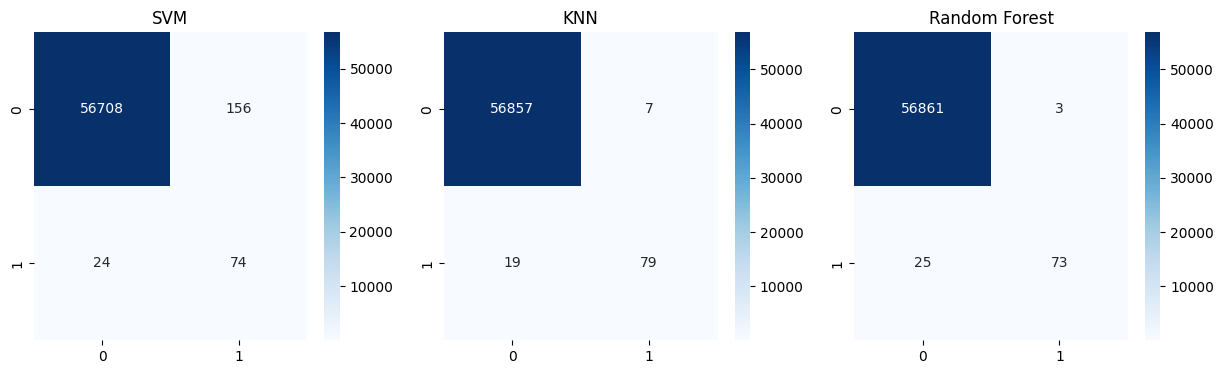

In [7]:
plt.figure(figsize=(15,4))

for i, (model_name, metrics) in enumerate(results.items(), 1):
    plt.subplot(1,3,i)
    sns.heatmap(metrics['Confusion Matrix'], annot=True, fmt='d', cmap='Blues')
    plt.title(model_name)

plt.show()

In [8]:
df_results = pd.DataFrame({
    model: {
        "Accuracy": res["Accuracy"],
        "Precision": res["Precision"],
        "Recall": res["Recall"],
        "F1-Score": res["F1-Score"]
    }
    for model, res in results.items()
}).T

df_results

,Accuracy,Precision,Recall,F1-Score
SVM,0.996840,0.321739,0.755102,0.451220
KNN,0.999544,0.918605,0.806122,0.858696
Random Forest,0.999508,0.960526,0.744898,0.839080


In [9]:
print("=== Discussion des résultats ===\n")

for model, metrics in results.items():
    print(f"{model}:")
    print(f"  - Accuracy : {metrics['Accuracy']:.4f}")
    print(f"  - Precision : {metrics['Precision']:.4f}")
    print(f"  - Recall : {metrics['Recall']:.4f}")
    print(f"  - F1-Score : {metrics['F1-Score']:.4f}\n")

print("""
Analyse :
- Les données sont très déséquilibrées : très peu de fraudes.
- Le Recall (capacité à détecter les fraudes) est la métrique la plus importante.
- En général :
  • Random Forest donne souvent le meilleur équilibre Precision/Recall.
  • SVM peut donner un bon Recall grâce à class_weight="balanced".
  • KNN est moins performant sur grandes données.
""")

=== Discussion des résultats ===

SVM:
  - Accuracy : 0.9968
  - Precision : 0.3217
  - Recall : 0.7551
  - F1-Score : 0.4512

KNN:
  - Accuracy : 0.9995
  - Precision : 0.9186
  - Recall : 0.8061
  - F1-Score : 0.8587

Random Forest:
  - Accuracy : 0.9995
  - Precision : 0.9605
  - Recall : 0.7449
  - F1-Score : 0.8391


Analyse :
- Les données sont très déséquilibrées : très peu de fraudes.
- Le Recall (capacité à détecter les fraudes) est la métrique la plus importante.
- En général :
  • Random Forest donne souvent le meilleur équilibre Precision/Recall.
  • SVM peut donner un bon Recall grâce à class_weight="balanced".
  • KNN est moins performant sur grandes données.

